Сгенерирован сигнал. Всего фотоэлектронов: 134


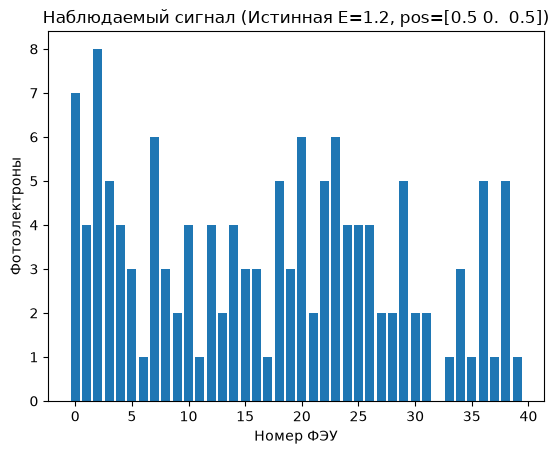

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
import arviz as az

np.random.seed(42)

class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R, self.N, self.r, self.a = R, N, r, a
        indices = np.arange(0, N, dtype=float) + 0.5
        phi = np.arccos(1 - 2 * indices / N)
        theta = np.pi * (1 + 5**0.5) * indices
        x = np.cos(theta) * np.sin(phi) * R
        y = np.sin(theta) * np.sin(phi) * R
        z = np.cos(phi) * R
        self.pmt_positions = np.column_stack((x, y, z))

def simulate_event_numpy(det, E, position=(0,0,0), Y=10000):
    N_photons = int(Y * E)
    cos_theta = np.random.uniform(-1, 1, N_photons)
    phi = np.random.uniform(0, 2*np.pi, N_photons)
    sin_theta = np.sqrt(1 - cos_theta**2)
    dirs = np.column_stack((sin_theta*np.cos(phi), sin_theta*np.sin(phi), cos_theta))
    
    start = np.array(position)
    b = 2 * np.dot(dirs, start)
    c = np.sum(start**2) - det.R**2
    t = (-b + np.sqrt(b**2 - 4*c)) / 2
    hit_points = start + t[:, np.newaxis] * dirs
    
    distances = np.linalg.norm(hit_points[:, np.newaxis, :] - det.pmt_positions, axis=2)
    hit_indices = np.argmin(distances, axis=1)
    is_hit = np.min(distances, axis=1) <= det.r
    
    pe_counts = np.zeros(det.N)
    for idx in hit_indices[is_hit]:
        pe_counts[idx] += 1
        
    pe_observed = np.random.poisson(pe_counts * det.a)
    return pe_observed

# Истинные параметры события (то, что мы потом будем восстанавливать)
true_E = 1.2
true_pos = np.array([0.5, 0.0, 0.5])
det = Detector()

#  "наблюдаемые" данные (сигнал с детектора)
observed_pe = simulate_event_numpy(det, E=true_E, position=true_pos)
print(f"Сгенерирован сигнал. Всего фотоэлектронов: {np.sum(observed_pe)}")

plt.bar(range(det.N), observed_pe)
plt.xlabel("Номер ФЭУ")
plt.ylabel("Фотоэлектроны")
plt.title(f"Наблюдаемый сигнал (Истинная E={true_E}, pos={true_pos})")
plt.show()

In [4]:
with pm.Model() as detector_model:
    E = pm.Uniform("E", lower=0, upper=3.0) 
    x = pm.Uniform("x", lower=-1.9, upper=1.9) 
    y = pm.Uniform("y", lower=-1.9, upper=1.9)
    z = pm.Uniform("z", lower=-1.9, upper=1.9)
    
    Y = 10000
    a_eff = 0.5
    
    dx = det.pmt_positions[:, 0] - x
    dy = det.pmt_positions[:, 1] - y
    dz = det.pmt_positions[:, 2] - z
    dist_sq = dx**2 + dy**2 + dz**2
    
    cos_alpha = (det.R**2 - (x**2 + y**2 + z**2) + dist_sq) / (2 * det.R * pt.sqrt(dist_sq))
    
    solid_angle = 2 * pt.pi * (1 - cos_alpha) 
    expected_pe = (Y * E * a_eff) * (solid_angle / (4 * pt.pi))
    
    obs = pm.Poisson("obs", mu=expected_pe, observed=observed_pe)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [E, x, y, z]


c:\Users\lizar\detector_simulation\.venv\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 11 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


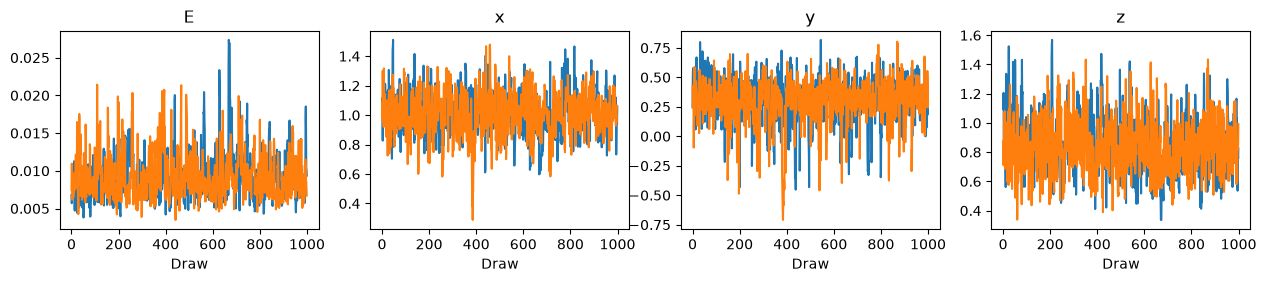

     mean      sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
E  0.0092  0.0031   0.0055    0.015      321      474  1.01   0.00018  0.0002
x    1.01    0.14     0.78      1.2      450      484  1.01     0.007   0.006
y     0.3    0.19   -0.046     0.56      621      613  1.00    0.0087   0.011
z    0.85    0.19     0.56      1.2      407      685  1.01    0.0095  0.0052


In [5]:
with detector_model:
    trace = pm.sample(1000, tune=1000, chains=2, target_accept=0.9)

az.plot_trace(trace, var_names=["E", "x", "y", "z"])
plt.show()

summary = az.summary(trace, var_names=["E", "x", "y", "z"])
print(summary)